In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv(r'C:\Users\DELL\Downloads\customer_segmentation.csv')


In [4]:
df.head()


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [25]:
df.info()

<class 'pandas.DataFrame'>
Index: 2216 entries, 0 to 2239
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2216 non-null   int64         
 1   Year_Birth           2216 non-null   int64         
 2   Education            2216 non-null   str           
 3   Marital_Status       2216 non-null   str           
 4   Income               2216 non-null   float64       
 5   Kidhome              2216 non-null   int64         
 6   Teenhome             2216 non-null   int64         
 7   Dt_Customer          2216 non-null   datetime64[us]
 8   Recency              2216 non-null   int64         
 9   MntWines             2216 non-null   int64         
 10  MntFruits            2216 non-null   int64         
 11  MntMeatProducts      2216 non-null   int64         
 12  MntFishProducts      2216 non-null   int64         
 13  MntSweetProducts     2216 non-null   int64       

In [8]:
df.isna()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2236,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2237,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2238,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [11]:
df.isna().sum().sum()

np.int64(24)

In [27]:
df.dropna()
median_income = df['Income'].median()

df['Income'] = df['Income'].fillna(median_income)

print(df['Income'].isnull().sum())

0


In [28]:
df.dropna( inplace=  True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_11440\1155634665.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna( inplace=  True)


In [29]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total_Spending,Total_Purchases
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.000000,2216.0,2216.0,2216.000000,2216.000000,2216.000000,2216.000000
mean,5588.353339,1968.820397,52247.251354,0.441787,0.505415,2013-07-10 11:29:27.509025,49.012635,305.091606,26.356047,166.995939,...,0.073105,0.064079,0.013538,0.009477,3.0,11.0,0.150271,57.179603,607.075361,12.557310
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,30.000000,5.000000,0.000000
25%,2814.750000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,24.000000,2.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,49.000000,69.000000,6.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,174.500000,8.000000,68.000000,...,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,56.000000,396.500000,12.000000
75%,8421.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-31 00:00:00,74.000000,505.000000,33.000000,232.250000,...,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,67.000000,1048.000000,18.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000,133.000000,2525.000000,32.000000
std,3249.376275,11.985554,25173.076661,0.536896,0.544181,NaN,28.948352,337.327920,39.793917,224.283273,...,0.260367,0.244950,0.115588,0.096907,0.0,0.0,0.357417,11.985554,602.900476,7.204611


In [30]:
df["Education"].value_counts()

Education
Graduation    1116
PhD            481
Master         365
2n Cycle       200
Basic           54
Name: count, dtype: int64

In [31]:
df["Marital_Status"].value_counts()

Marital_Status
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [13]:
df["Dt_Customer"] = pd.to_datetime (df["Dt_Customer"], dayfirst= True)  
df["Dt_Customer"] = pd.to_datetime (df["Dt_Customer"] , dayfirst= True )                      

In [32]:
df.info()


<class 'pandas.DataFrame'>
Index: 2216 entries, 0 to 2239
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2216 non-null   int64         
 1   Year_Birth           2216 non-null   int64         
 2   Education            2216 non-null   str           
 3   Marital_Status       2216 non-null   str           
 4   Income               2216 non-null   float64       
 5   Kidhome              2216 non-null   int64         
 6   Teenhome             2216 non-null   int64         
 7   Dt_Customer          2216 non-null   datetime64[us]
 8   Recency              2216 non-null   int64         
 9   MntWines             2216 non-null   int64         
 10  MntFruits            2216 non-null   int64         
 11  MntMeatProducts      2216 non-null   int64         
 12  MntFishProducts      2216 non-null   int64         
 13  MntSweetProducts     2216 non-null   int64       

In [19]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='str')

In [15]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64

In [34]:
df.drop_duplicates()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total_Spending,Total_Purchases
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,3,11,1,69,1617,22
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,3,11,0,72,27,4
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,3,11,0,61,776,20
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,3,11,0,42,53,6
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,3,11,0,45,422,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,0,0,0,0,3,11,0,59,1341,16
2236,4001,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,...,0,1,0,0,3,11,0,80,444,15
2237,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,...,0,0,0,0,3,11,0,45,1241,18
2238,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,0,0,0,0,3,11,0,70,843,21


In [25]:
df.nunique()

ID                     2216
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             662
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         554
MntFishProducts         182
MntSweetProducts        176
MntGoldProds            212
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [16]:
df["ID"].nunique()

2216

In [17]:
df["Income"].nunique()

1974

In [19]:
df['Income'] = df['Income'].fillna(
    df['Income'].median()
)

In [35]:
# Customer age
df['Age'] = 2026 - df['Year_Birth']

# Total spending
spending_cols = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

df['Total_Spending'] = df[spending_cols].sum(axis=1)

# Total purchases
purchase_cols = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

df['Total_Purchases'] = df[purchase_cols].sum(axis=1)

print(df[['Age', 'Income',
          'Total_Spending',
          'Total_Purchases']].head())

   Age   Income  Total_Spending  Total_Purchases
0   69  58138.0            1617               22
1   72  46344.0              27                4
2   61  71613.0             776               20
3   42  26646.0              53                6
4   45  58293.0             422               14


In [38]:
# Find unusually high income
print(df[df['Income'] > 200000][
    ['ID', 'Income']
])

# Find unusually old birth years
print(df[df['Year_Birth'] < 1940][
    ['ID', 'Year_Birth']
])

        ID    Income
2233  9432  666666.0
        ID  Year_Birth
192   7829        1900
239  11004        1893
339   1150        1899


In [43]:
df['Dt_Customer'] = pd.to_datetime(
    df['Dt_Customer'],
    format='%d-%m-%Y'
)

print(df['Dt_Customer'].dtype)

print("Missing Values:")
print(df.isnull().sum().sum())

print("Duplicate Rows:")
print(df.duplicated().sum())

print("Dataset Shape:")
print(df.shape)

print("Data Types:")
print(df.dtypes)

datetime64[us]
Missing Values:
0
Duplicate Rows:
0
Dataset Shape:
(2216, 32)
Data Types:
ID                              int64
Year_Birth                      int64
Education                         str
Marital_Status                    str
Income                        float64
Kidhome                         int64
Teenhome                        int64
Dt_Customer            datetime64[us]
Recency                         int64
MntWines                        int64
MntFruits                       int64
MntMeatProducts                 int64
MntFishProducts                 int64
MntSweetProducts                int64
MntGoldProds                    int64
NumDealsPurchases               int64
NumWebPurchases                 int64
NumCatalogPurchases             int64
NumStorePurchases               int64
NumWebVisitsMonth               int64
AcceptedCmp3                    int64
AcceptedCmp4                    int64
AcceptedCmp5                    int64
AcceptedCmp1                    int64

In [44]:
# Age (dataset reference year 2014)
df['Age'] = 2014 - df['Year_Birth']

# Total Spending
df['Total_Spending'] = df[
    ['MntWines', 'MntFruits', 'MntMeatProducts',
     'MntFishProducts', 'MntSweetProducts',
     'MntGoldProds']
].sum(axis=1)

# Total Purchases
df['Total_Purchases'] = df[
    ['NumWebPurchases', 'NumCatalogPurchases',
     'NumStorePurchases']
].sum(axis=1)

# Family Size
df['Family_Size'] = (
    2 + df['Kidhome'] + df['Teenhome']
)

# Total Children
df['Total_Children'] = (
    df['Kidhome'] + df['Teenhome']
)

# Parent or not
df['Is_Parent'] = (
    df['Total_Children'] > 0
).astype(int)

# Campaign Acceptance
campaign_cols = [
    'AcceptedCmp1', 'AcceptedCmp2',
    'AcceptedCmp3', 'AcceptedCmp4',
    'AcceptedCmp5', 'Response'
]

df['Total_Campaign_Accepted'] = (
    df[campaign_cols].sum(axis=1)
)

print(df.head())

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  Z_CostContact  Z_Revenue  Response  \
0  2012-09-04       58       635  ...              3         11         1   
1  2014-03-08       38        11  ...              3         11         0   
2  2013-08-21       26       426  ...              3         11         0   
3  2014-02-10       26        11  ...              3         11         0   
4  2014-01-19       94       173  ...              3         11         0   

   Age  Total_Spending  Total_Purchases  Family_Size  Total_Children

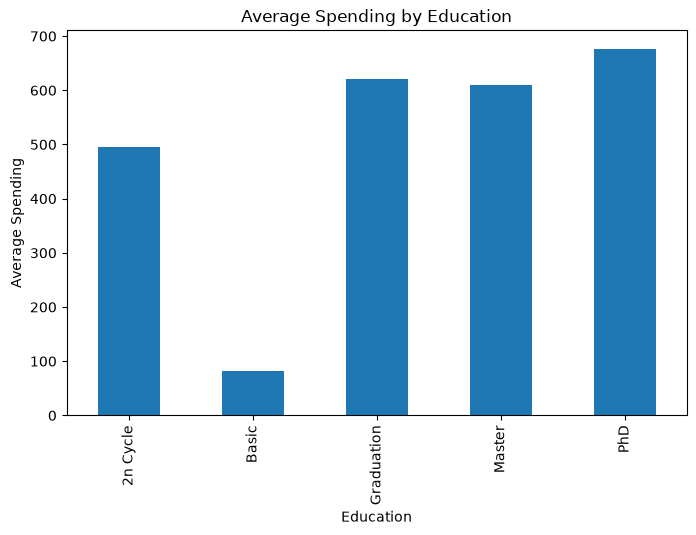

In [46]:
df.groupby('Education')['Total_Spending'].mean().plot(
    kind='bar', figsize=(8,5)
)

plt.title('Average Spending by Education')
plt.ylabel('Average Spending')
plt.show()

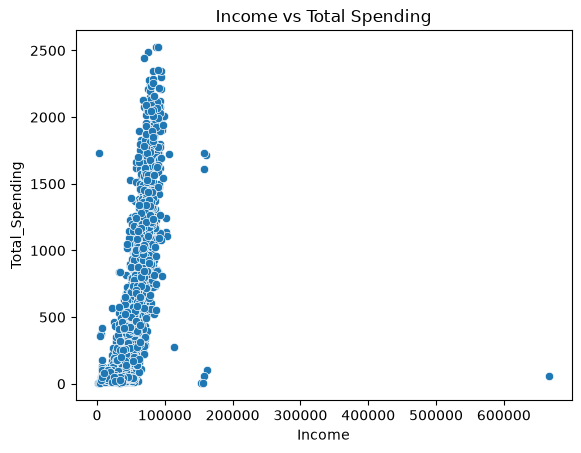

In [47]:
sns.scatterplot(
    data=df,
    x='Income',
    y='Total_Spending'
)

plt.title('Income vs Total Spending')
plt.show()

In [48]:
new_columns = [
    'Age',
    'Total_Spending',
    'Total_Purchases',
    'Family_Size',
    'Total_Children',
    'Is_Parent',
    'Total_Campaign_Accepted'
]

print(df[new_columns].head())

   Age  Total_Spending  Total_Purchases  Family_Size  Total_Children  \
0   57            1617               22            2               0   
1   60              27                4            4               2   
2   49             776               20            2               0   
3   30              53                6            3               1   
4   33             422               14            3               1   

   Is_Parent  Total_Campaign_Accepted  
0          0                        1  
1          1                        0  
2          0                        0  
3          1                        0  
4          1                        0  


In [49]:
df[['Age', 'Income',
    'Total_Spending',
    'Total_Purchases']].describe()

,Age,Income,Total_Spending,Total_Purchases
count,2216.000000,2216.000000,2216.000000,2216.000000
mean,45.179603,52247.251354,607.075361,12.557310
std,11.985554,25173.076661,602.900476,7.204611
min,18.000000,1730.000000,5.000000,0.000000
25%,37.000000,35303.000000,69.000000,6.000000
50%,44.000000,51381.500000,396.500000,12.000000
75%,55.000000,68522.000000,1048.000000,18.000000
max,121.000000,666666.000000,2525.000000,32.000000


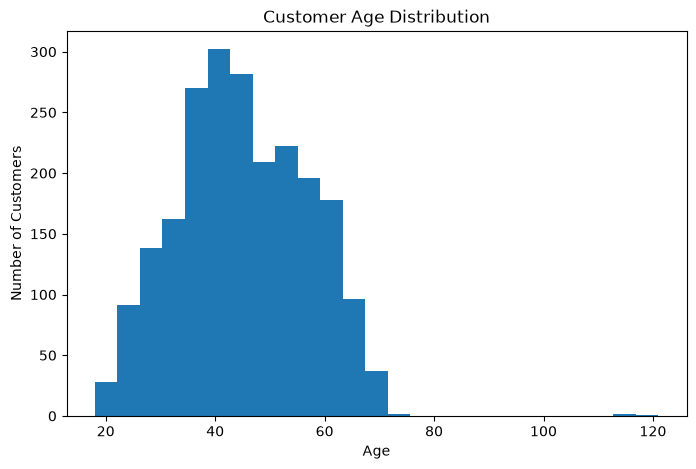

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

plt.hist(df['Age'], bins=25)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

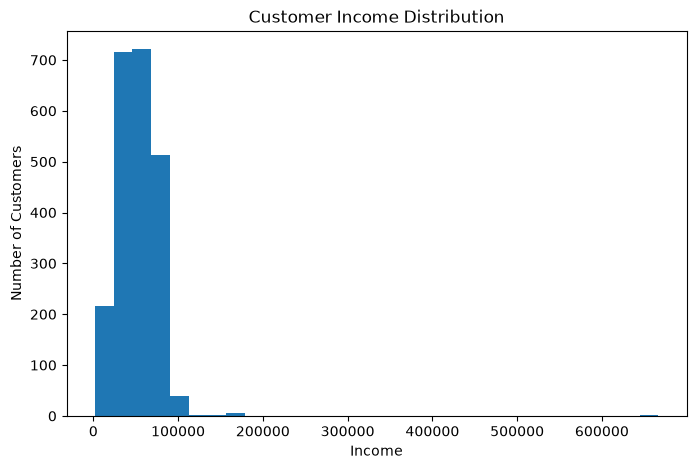

In [51]:
plt.figure(figsize=(8,5))

plt.hist(df['Income'], bins=30)

plt.title('Customer Income Distribution')
plt.xlabel('Income')
plt.ylabel('Number of Customers')

plt.show()

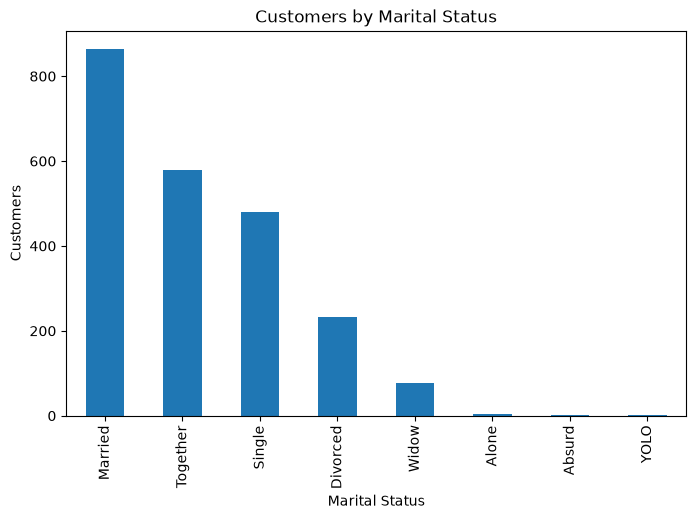

In [7]:
plt.figure(figsize=(8,5))

df['Marital_Status'].value_counts().plot(
    kind='bar'
)

plt.title('Customers by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Customers')

plt.show()

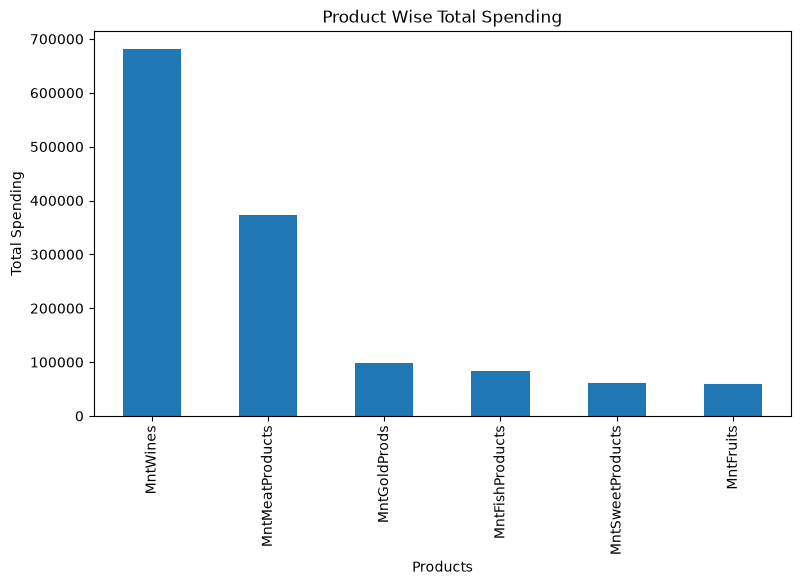

In [8]:
spending_cols = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

product_spending = df[spending_cols].sum()

product_spending.sort_values(
    ascending=False
).plot(kind='bar', figsize=(9,5))

plt.title('Product Wise Total Spending')
plt.xlabel('Products')
plt.ylabel('Total Spending')

plt.show()

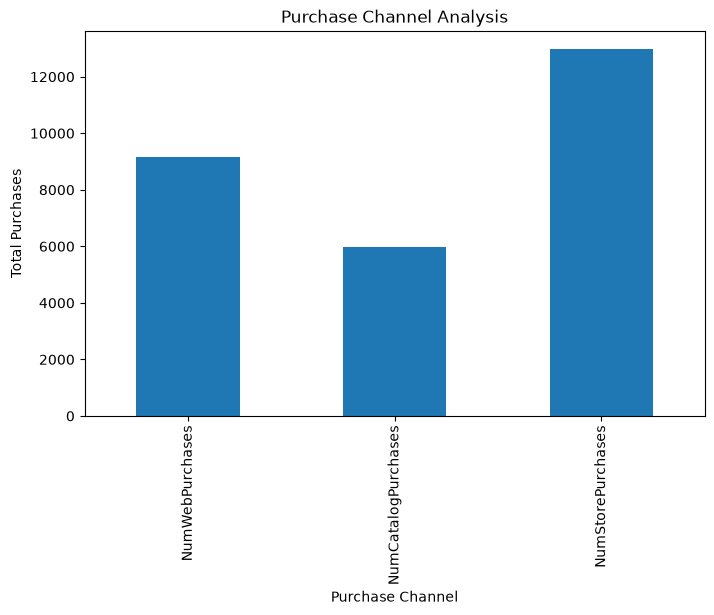

In [9]:
purchase_cols = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

purchase_data = df[purchase_cols].sum()

purchase_data.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Purchase Channel Analysis')
plt.xlabel('Purchase Channel')
plt.ylabel('Total Purchases')

plt.show()

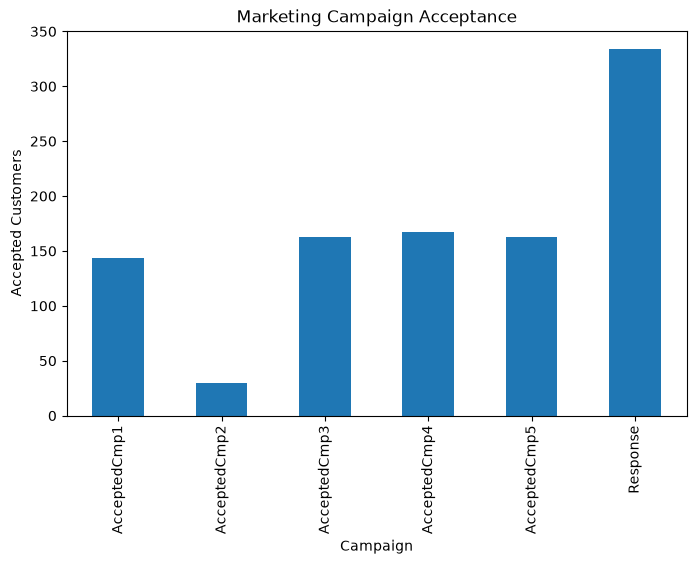

In [10]:
campaign_cols = [
    'AcceptedCmp1',
    'AcceptedCmp2',
    'AcceptedCmp3',
    'AcceptedCmp4',
    'AcceptedCmp5',
    'Response'
]

campaign_data = df[campaign_cols].sum()

campaign_data.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Marketing Campaign Acceptance')
plt.xlabel('Campaign')
plt.ylabel('Accepted Customers')

plt.show()

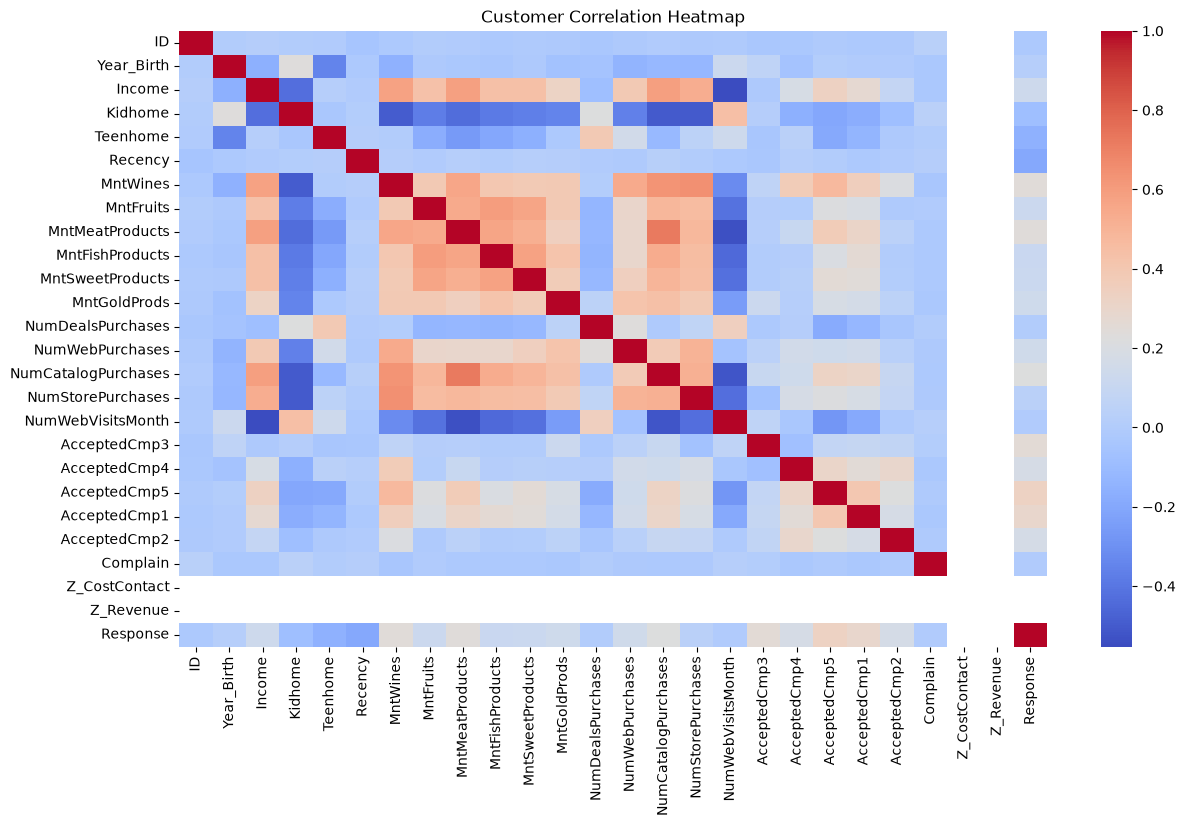

In [11]:
plt.figure(figsize=(14,8))

numeric_df = df.select_dtypes(
    include='number'
)

sns.heatmap(
    numeric_df.corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Customer Correlation Heatmap')

plt.show()

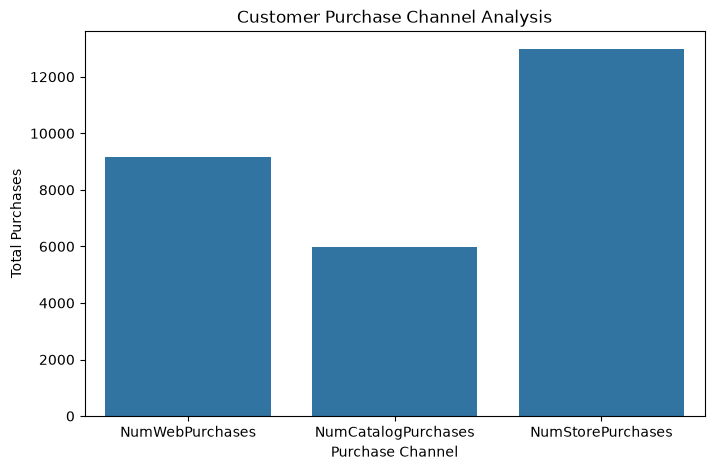

In [12]:
purchase_cols = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

purchase_data = df[purchase_cols].sum()

plt.figure(figsize=(8,5))

sns.barplot(
    x=purchase_data.index,
    y=purchase_data.values
)

plt.title('Customer Purchase Channel Analysis')
plt.xlabel('Purchase Channel')
plt.ylabel('Total Purchases')

plt.show()

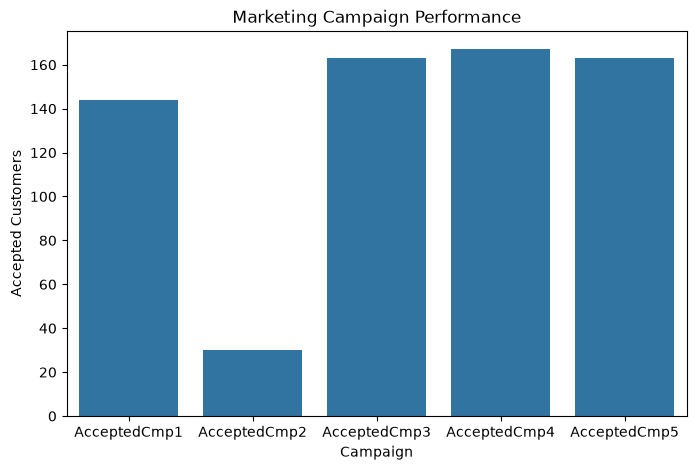

In [13]:
campaign_cols = [
    'AcceptedCmp1',
    'AcceptedCmp2',
    'AcceptedCmp3',
    'AcceptedCmp4',
    'AcceptedCmp5'
]

campaign_data = df[campaign_cols].sum()

plt.figure(figsize=(8,5))

sns.barplot(
    x=campaign_data.index,
    y=campaign_data.values
)

plt.title('Marketing Campaign Performance')
plt.xlabel('Campaign')
plt.ylabel('Accepted Customers')

plt.show()

In [15]:
print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


In [17]:
spending_cols = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

df['Total_Spending'] = df[spending_cols].sum(axis=1)

print(df['Total_Spending'].head())

0    1617
1      27
2     776
3      53
4     422
Name: Total_Spending, dtype: int64


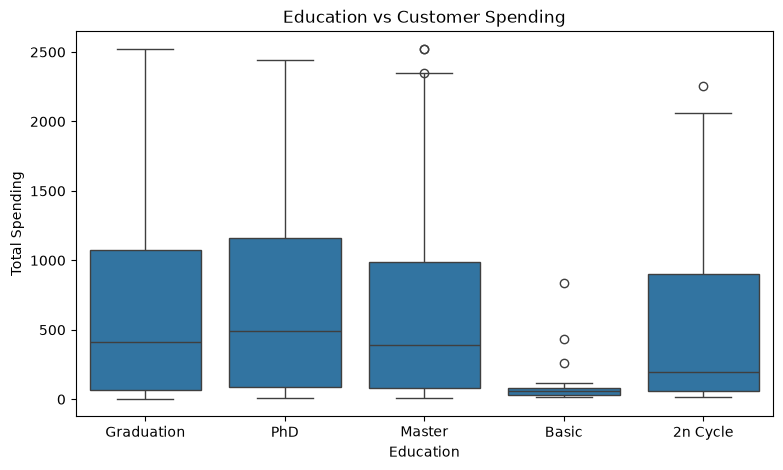

In [19]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='Education',
    y='Total_Spending'
)

plt.title('Education vs Customer Spending')
plt.xlabel('Education')
plt.ylabel('Total Spending')

plt.show()

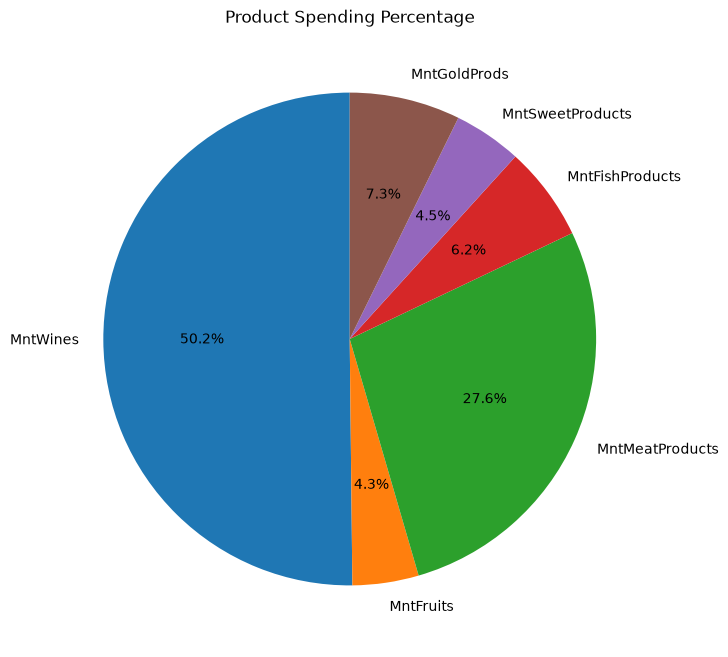

In [20]:
product_data = df[spending_cols].sum()

plt.figure(figsize=(8,8))

plt.pie(
    product_data,
    labels=product_data.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Product Spending Percentage')

plt.show()

In [ ]:
features = [
    'Age',
    'Income',
    'Recency',
    'Total_Spending',
    'Total_Purchases',
    'Family_Size'
]

print(features)

['Age', 'Income', 'Recency', 'Total_Spending', 'Total_Purchases', 'Family_Size']


In [26]:
print("Available Columns:")
print(df.columns.tolist())

print("\nMissing Features:")
print(set(features) - set(df.columns))

Available Columns:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'Total_Spending']

Missing Features:
{'Age', 'Family_Size', 'Total_Purchases'}


In [28]:
print("Available Columns:")
print(df.columns.tolist())

print("\nFeatures:")
print(features)



Available Columns:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'Total_Spending']

Features:
['Age', 'Income', 'Recency', 'Total_Spending', 'Total_Purchases', 'Family_Size']


In [30]:
# Clean column names
df.columns = df.columns.str.strip()

# Create Age
df['Age'] = 2014 - df['Year_Birth']

# Create Total Spending
spending_cols = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

df['Total_Spending'] = df[spending_cols].sum(axis=1)

# Create Total Purchases
purchase_cols = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

df['Total_Purchases'] = df[purchase_cols].sum(axis=1)

# Create Family Size
df['Family_Size'] = (
    2 + df['Kidhome'] + df['Teenhome']
)

print("All features created successfully!")

All features created successfully!


In [ ]:
# Keep realistic customer records for clustering
valid_mask = (
    df['Age'].between(18, 100) &
    df['Income'].between(0, 200000)
)

model_data = df.loc[valid_mask, features].dropna().copy()

print("Original customers:", len(df))
print("Customers used for clustering:", len(model_data))
print("Excluded records:", len(df) - len(model_data))

Original customers: 2240
Customers used for clustering: 2212
Excluded records: 28


In [ ]:
features = [
    'Age',
    'Income',
    'Recency',
    'Total_Spending',
    'Total_Purchases',
    'Family_Size'
]

X = df[features].copy()

print(X.head())

   Age   Income  Recency  Total_Spending  Total_Purchases  Family_Size
0   57  58138.0       58            1617               22            2
1   60  46344.0       38              27                4            4
2   49  71613.0       26             776               20            2
3   30  26646.0       26              53                6            3
4   33  58293.0       94             422               14            3


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(model_data)

print(X_scaled[:5])

[[ 1.01835202  0.28710487  0.31035323  1.67624537  1.30946091 -1.26459792]
 [ 1.27478522 -0.26088203 -0.38081349 -0.96329696 -1.18922094  1.4045725 ]
 [ 0.33453017  0.9131964  -0.79551352  0.28011009  1.03182959 -1.26459792]
 [-1.28954674 -1.17611401 -0.79551352 -0.92013463 -0.91158963  0.06998729]
 [-1.03311355  0.29430667  1.55445333 -0.3075616   0.19893564  0.06998729]]


In [34]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

model_data['Cluster'] = kmeans.fit_predict(X_scaled)

print(model_data[['Age', 'Income',
                  'Total_Spending',
                  'Total_Purchases',
                  'Cluster']].head(10))

   Age   Income  Total_Spending  Total_Purchases  Cluster
0   57  58138.0            1617               22        2
1   60  46344.0              27                4        1
2   49  71613.0             776               20        2
3   30  26646.0              53                6        3
4   33  58293.0             422               14        0
5   47  62513.0             716               20        0
6   43  55635.0             590               17        0
7   29  33454.0             169                8        3
8   40  30351.0              46                5        3
9   64   5648.0              49                1        1


In [35]:
print(model_data['Cluster'].value_counts().sort_index())

Cluster
0    588
1    432
2    541
3    651
Name: count, dtype: int64


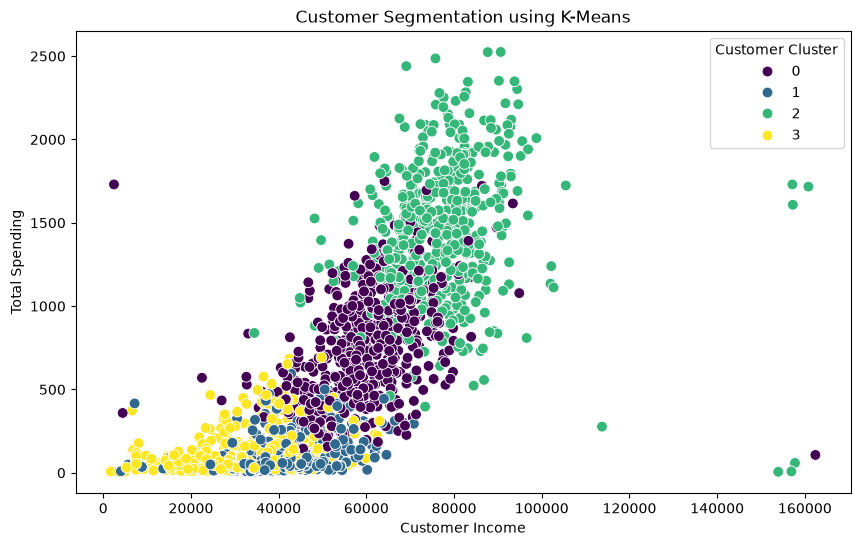

In [36]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=model_data,
    x='Income',
    y='Total_Spending',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Customer Income')
plt.ylabel('Total Spending')

plt.legend(title='Customer Cluster')
plt.show()

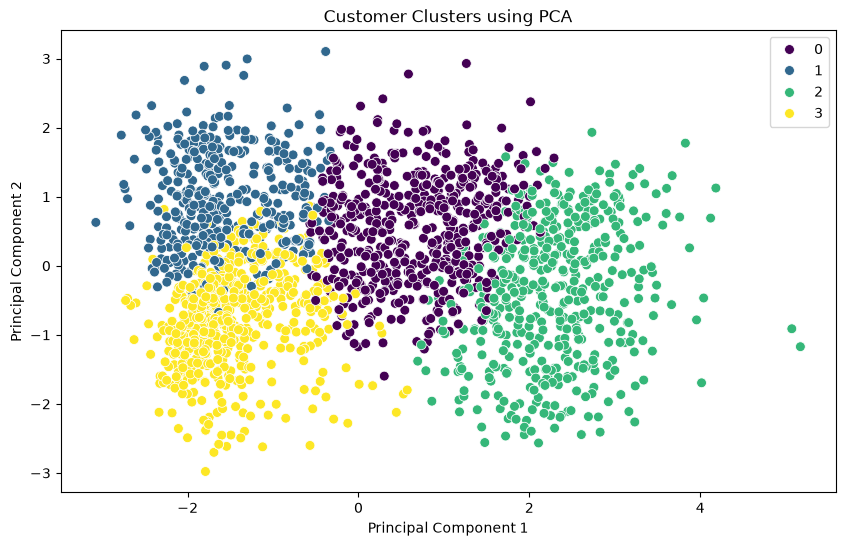

In [37]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)

plt.figure(figsize=(10,6))

sns.scatterplot(
    x=pca_data[:, 0],
    y=pca_data[:, 1],
    hue=model_data['Cluster'].values,
    palette='viridis',
    s=50
)

plt.title('Customer Clusters using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

In [ ]:
cluster_summary = model_data.groupby('Cluster')[
    features
].mean().round(2)

print(cluster_summary)

           Age    Income  Recency  Total_Spending  Total_Purchases  \
Cluster                                                              
0        50.70  59922.82    47.15          748.28            17.44   
1        49.91  41236.86    49.36          126.46             6.68   
2        44.82  77447.98    50.49         1433.63            19.70   
3        37.04  30698.30    49.26          112.24             6.15   

         Family_Size  
Cluster               
0               3.06  
1               3.98  
2               2.16  
3               2.82  


In [ ]:
print(model_data['Cluster'].value_counts())

Cluster
3    651
0    588
2    541
1    432
Name: count, dtype: int64


In [40]:
score = silhouette_score(
    X_scaled,
    model_data['Cluster']
)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.211


In [41]:
model_data.to_csv(
    'customer_kmeans_results.csv',
    index=False
)

print("Customer clustering results saved!")

Customer clustering results saved!


In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


In [ ]:
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

print(wcss)

[13271.999999999998, 8224.367969789912, 7123.248659465849, 6340.756752886515, 5750.241908619041, 5211.707304420452, 4787.679232473165, 4476.177509776571, 4214.047235321472, 3982.8715721144267]


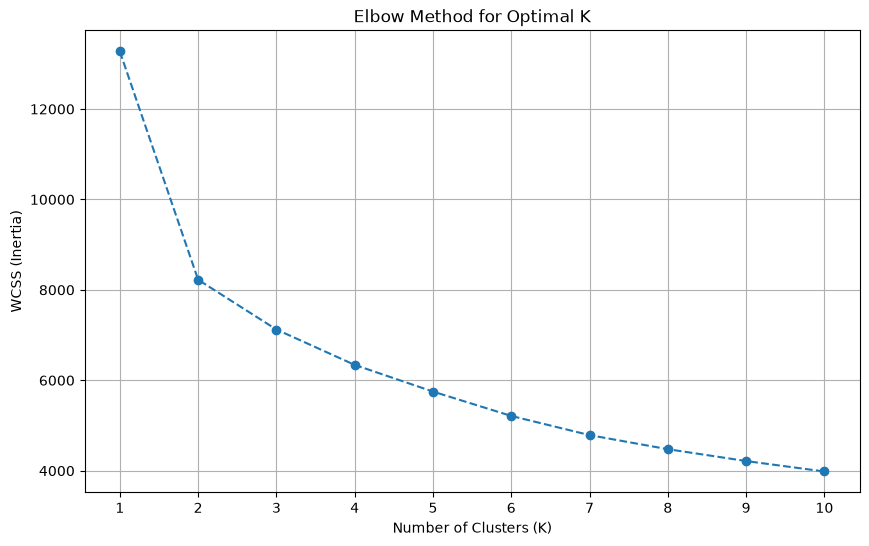

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 11),
    wcss,
    marker='o',
    linestyle='--'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [ ]:
silhouette_scores = []

for k in range(2, 11):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

print("Silhouette Scores:")

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: {score:.3f}")

Silhouette Scores:
K=2: 0.336
K=3: 0.252
K=4: 0.211
K=5: 0.220
K=6: 0.207
K=7: 0.216
K=8: 0.219
K=9: 0.220
K=10: 0.219


In [ ]:
optimal_k = 4

final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

model_data['Cluster'] = final_kmeans.fit_predict(X_scaled)

print("Optimal K:", optimal_k)
print(model_data['Cluster'].value_counts().sort_index())

Optimal K: 4
Cluster
0    588
1    432
2    541
3    651
Name: count, dtype: int64


In [ ]:
optimal_k = 2

from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

model_data['Cluster'] = kmeans.fit_predict(X_scaled)

print("Customer Segmentation Completed!")

In [ ]:
print(model_data['Cluster'].value_counts().sort_index())

In [ ]:
cluster_summary = model_data.groupby('Cluster').agg({
    'Age': 'mean',
    'Income': 'mean',
    'Total_Spending': 'mean',
    'Total_Purchases': 'mean',
    'Family_Size': 'mean'
}).round(2)

print(cluster_summary)